# Week 5: length-scale lower-bound sensitivity

Compare **`0.001`, `0.0001`, and `0.00001`** as length-scale lower bounds for all eight functions and five package kernels, using observations **through week 5**. Keep each function's configured maximum length cap fixed and the WhiteKernel noise bounds fixed at **`(1e-8, 1e1)`**. This isolates the length-scale constraint from the separate [noise-floor analysis](03_length_scale_sensitivity.ipynb).

Each fit starts fresh with the package kernel initialization and configured target normalization, seed, and optimizer restarts. On unit-range inputs, `0.001` is 0.1% of a coordinate's range; these length scales are input distances, not output/noise magnitudes. Relaxing the bound allows sharper variation but does not force shorter fitted scales. No shared defaults, data, or candidate exports are changed.

In [1]:
%matplotlib inline
from pathlib import Path
import warnings

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning

from bayesian_bbo import CONFIG, FUNCTION_SPECS
from bayesian_bbo.data import load_observations
from bayesian_bbo.kernels import make_comparison_kernels
from bayesian_bbo.surrogate import fit_surrogate

WEEK = 5
FUNCTION_IDS = tuple(FUNCTION_SPECS)
LENGTH_FLOORS = (1e-3, 1e-4, 1e-5)
LENGTH_CAPS = CONFIG['length_caps']
NOISE_BOUNDS = (1e-8, 1e1)
data_candidates = [Path('../../data'), Path('data'), Path('../data')]
matches = [path.resolve() for path in data_candidates if (path / 'function_1').is_dir()]
if not matches:
    raise FileNotFoundError('Could not find the data directory from the notebook working directory.')
data_root = matches[0]
observations_by_function = {
    function_id: load_observations(data_root, function_id, up_to_week=WEEK)
    for function_id in FUNCTION_IDS
}
plt.style.use('seaborn-v0_8-whitegrid')
print(f'Training cutoff: week {WEEK}; optimizer restarts: {CONFIG["n_restarts_optimizer"]}')
print(f'Noise bounds fixed at {NOISE_BOUNDS}; data root: {data_root}')

Training cutoff: week 5; optimizer restarts: 10
Noise bounds fixed at (1e-08, 10.0); data root: /home/pabloncho/repositories/bayesian-bbo/data


In [2]:
fit_records = []
warning_records = []
for function_id, observations in observations_by_function.items():
    for length_floor in LENGTH_FLOORS:
        kernels = make_comparison_kernels(observations.dimension, LENGTH_CAPS[function_id])
        for kernel_name, kernel in kernels.items():
            kernel.set_params(
                k1__k2__length_scale_bounds=(length_floor, LENGTH_CAPS[function_id]),
                k2__noise_level_bounds=NOISE_BOUNDS,
            )
            with warnings.catch_warnings(record=True) as fit_warnings:
                warnings.simplefilter('always')
                model = fit_surrogate(observations, kernel=kernel)
            for warning in fit_warnings:
                warning_records.append({
                    'function_id': function_id, 'kernel': kernel_name, 'length_floor': length_floor,
                    'category': warning.category.__name__, 'message': str(warning.message),
                })
            scales = np.atleast_1d(model.kernel_.k1.k2.length_scale)
            fit_records.append({
                'function_id': function_id, 'kernel': kernel_name, 'length_floor': length_floor,
                'max_log_marginal_likelihood': float(model.log_marginal_likelihood_value_),
                'fitted_length_scales': tuple(float(value) for value in scales),
                'min_fitted_length_scale': float(scales.min()),
                'scales_at_lower_bound': int(np.count_nonzero(
                    np.isclose(scales, length_floor, rtol=1e-5, atol=0.0)
                )),
                'fitted_noise': float(model.kernel_.k2.noise_level),
                'convergence_warnings': sum(
                    issubclass(warning.category, ConvergenceWarning) for warning in fit_warnings
                ),
            })
    print(f'Function {function_id}: {len(LENGTH_FLOORS) * len(kernels)} fits completed')

length_floor_results = pd.DataFrame(fit_records).sort_values(
    ['function_id', 'kernel', 'length_floor']
).reset_index(drop=True)
baseline = length_floor_results.loc[length_floor_results.length_floor == LENGTH_FLOORS[0], [
    'function_id', 'kernel', 'max_log_marginal_likelihood',
]].rename(columns={'max_log_marginal_likelihood': 'baseline_lml'})
length_floor_results = length_floor_results.merge(
    baseline, on=['function_id', 'kernel'], validate='many_to_one',
)
length_floor_results['lml_gain'] = length_floor_results.max_log_marginal_likelihood - length_floor_results.baseline_lml
fit_warning_details = pd.DataFrame(warning_records, columns=[
    'function_id', 'kernel', 'length_floor', 'category', 'message',
])
print(f'{len(length_floor_results)} fits; {len(fit_warning_details)} warnings recorded in fit_warning_details.')

Function 1: 15 fits completed


Function 2: 15 fits completed


Function 3: 15 fits completed


Function 4: 15 fits completed


Function 5: 15 fits completed


Function 6: 15 fits completed


Function 7: 15 fits completed


Function 8: 15 fits completed
120 fits; 86 warnings recorded in fit_warning_details.


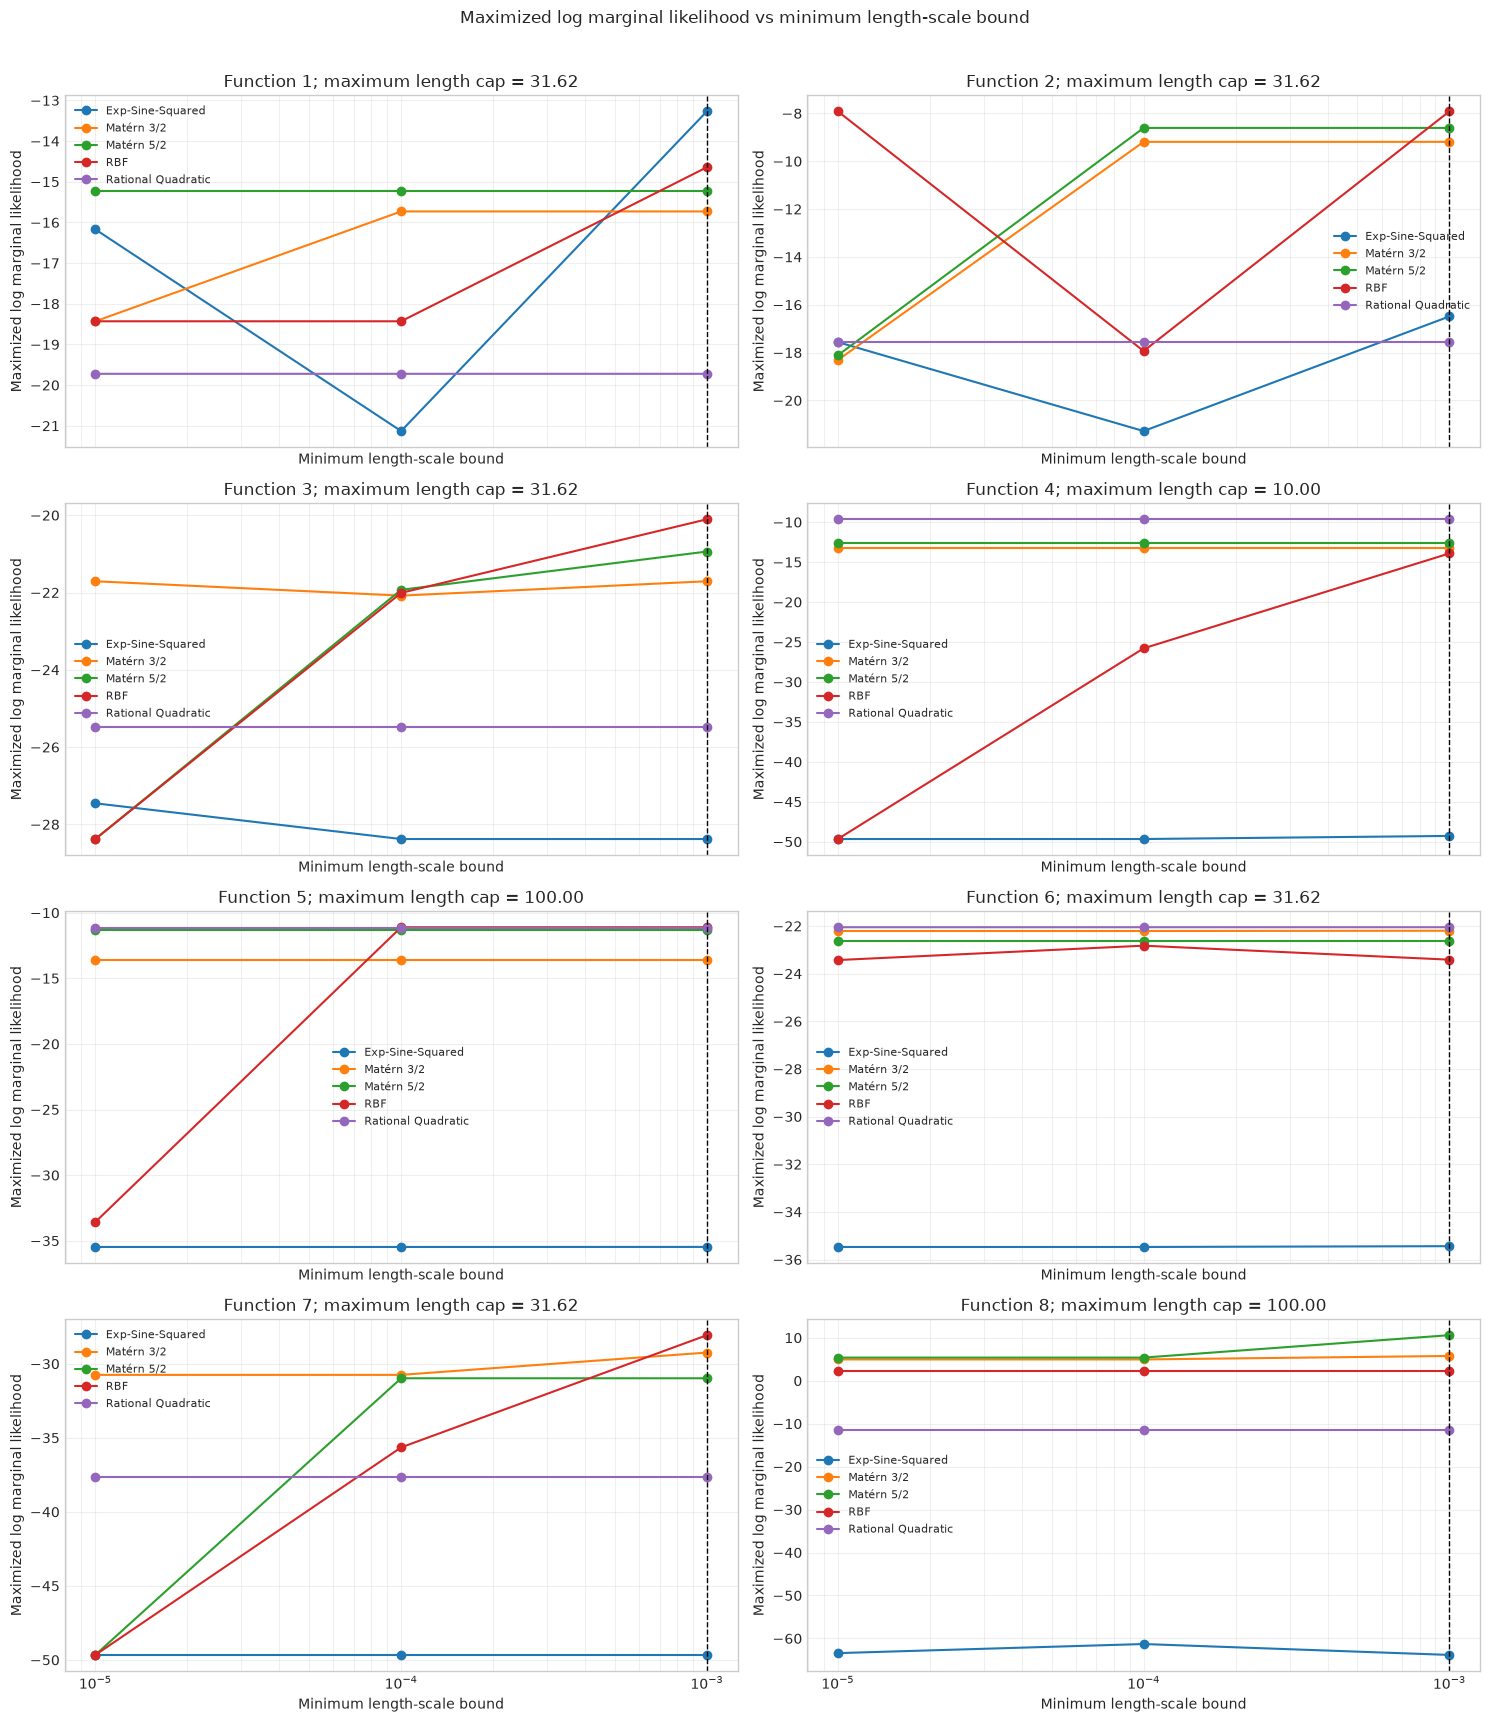

In [3]:
figure, axes = plt.subplots(4, 2, figsize=(15, 17), sharex=True, sharey=False)
for function_id, ax in zip(FUNCTION_IDS, axes.ravel()):
    rows = length_floor_results.loc[length_floor_results.function_id == function_id]
    for kernel_name, kernel_rows in rows.groupby('kernel', sort=False):
        ax.plot(
            kernel_rows.length_floor, kernel_rows.max_log_marginal_likelihood,
            marker='o', label=kernel_name,
        )
    ax.axvline(LENGTH_FLOORS[0], color='black', linestyle='--', linewidth=1)
    ax.set_xscale('log')
    ax.set_title(f'Function {function_id}; maximum length cap = {LENGTH_CAPS[function_id]:.2f}')
    ax.set_xlabel('Minimum length-scale bound')
    ax.set_ylabel('Maximized log marginal likelihood')
    ax.grid(True, which='both', alpha=0.3)
    ax.legend(fontsize=8)
figure.suptitle('Maximized log marginal likelihood vs minimum length-scale bound', y=1.01)
figure.tight_layout()
plt.show()

## Compare fitted scales and likelihood with the `0.001` baseline

The table reports each fit's smallest length scale, the LML gain over the same function/kernel at `0.001`, and how many length-scale parameters reached their lower bound. Full fitted scale tuples remain in `length_floor_results`: Matérn and RBF have one per input coordinate; Rational Quadratic and Exp-Sine-Squared use an isotropic scale.

If the baseline scales remain well above `0.001`, the existing lower bound is not directly restricting that solution. Likelihood changes after relaxing it may still arise from different local optima: changing bounds changes the log-uniform random restarts even with the same seed. A negative gain indicates numerical/optimizer sensitivity, because the old optimum remains feasible. A positive gain alone does not establish that the newly allowed shorter scales were necessary or that predictions improved.

Very short scales can produce narrow spikes and little information sharing between observations. Check held-out predictive accuracy, uncertainty calibration, and candidate stability before changing shared defaults. Warnings unrelated to the length floor are retained and labelled separately.

In [4]:
length_floor_summary = length_floor_results.pivot(
    index=['function_id', 'kernel'], columns='length_floor',
    values=['min_fitted_length_scale', 'lml_gain', 'scales_at_lower_bound'],
).reindex(columns=LENGTH_FLOORS, level='length_floor')
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(length_floor_summary)
print('Number of function/kernel fits with at least one length scale at its lower bound:')
display(length_floor_results.assign(at_bound=length_floor_results.scales_at_lower_bound > 0).groupby(
    'length_floor'
).at_bound.sum().reindex(LENGTH_FLOORS))
print('Warnings specifically about a length-scale lower bound:')
lower_bound_warnings = fit_warning_details.loc[
    fit_warning_details.message.str.contains('length_scale', regex=False)
    & fit_warning_details.message.str.contains('lower bound', regex=False)
]
with pd.option_context('display.max_colwidth', None, 'display.max_rows', None):
    display(lower_bound_warnings)

min_fitted_length_scale                      \
length_floor                                   0.00100   0.00010   0.00001   
function_id kernel                                                           
1           Exp-Sine-Squared                  0.011507  0.000585  0.000081   
            Matérn 3/2                        0.027743  0.027743  0.000020   
            Matérn 5/2                        0.025747  0.025747  0.025747   
            RBF                               0.020937  0.000345  0.000020   
            Rational Quadratic                0.037767  0.037767  0.037769   
2           Exp-Sine-Squared                  0.016829  0.017059  0.005640   
            Matérn 3/2                        0.082560  0.082560  0.000018   
            Matérn 5/2                        0.072921  0.072921  0.000760   
            RBF                               0.053759  0.001143  0.053759   
            Rational Quadratic                0.065996  0.065996  0.065996   
3           Exp-Sine-Squared                  0.001618  0.000180  0.003744   
            Matérn 3/2                        0.027345  0.364281  0.027345   
            Matérn 5/2                        0.309306  0.020002  0.003328   
            RBF                               0.157668  0.014361  0.000010   
            Rational Quadratic                0.216256  0.216256  0.216256   
4           Exp-Sine-Squared                  0.024897  0.000100  0.000010   
            Matérn 3/2                        3.015428  3.015410  3.015410   
            Matérn 5/2                        1.525762  1.525763  1.525763   
            RBF                               0.666439  0.182236  0.000010   
            Rational Quadratic                2.204335  2.204326  2.204324   
5           Exp-Sine-Squared                  0.006006  0.000190  0.000021   
            Matérn 3/2                        3.219592  3.219606  3.219606   
            Matérn 5/2                        1.814580  1.814581  1.814579   
            RBF                               0.698141  0.698141  0.006693   
            Rational Quadratic                1.503847  1.503846  1.503846   
6           Exp-Sine-Squared                  0.005033  0.000585  0.000103   
            Matérn 3/2                        1.290908  1.278281  1.278281   
            Matérn 5/2                        0.721391  0.721391  0.721396   
            RBF                               0.279956  0.237732  0.114755   
            Rational Quadratic                1.104475  1.104426  1.104427   
7           Exp-Sine-Squared                  0.001618  0.000585  0.000010   
            Matérn 3/2                        0.289332  0.220556  0.220553   
            Matérn 5/2                        0.211831  0.211815  0.015296   
            RBF                               0.231277  0.034207  0.000014   
            Rational Quadratic                0.343884  0.343883  0.343885   
8           Exp-Sine-Squared                  0.006016  0.001966  0.000095   
            Matérn 3/2                        5.756660  3.897554  3.897554   
            Matérn 5/2                        4.140275  1.813531  1.813531   
            RBF                               1.105323  1.105320  1.105318   
            Rational Quadratic                7.695619  7.695597  7.695661   

                               lml_gain                              \
length_floor                    0.00100       0.00010       0.00001   
function_id kernel                                                    
1           Exp-Sine-Squared        0.0 -7.861455e+00 -2.902132e+00   
            Matérn 3/2              0.0 -5.197087e-11 -2.700484e+00   
            Matérn 5/2              0.0 -6.501466e-13 -7.070788e-11   
            RBF                     0.0 -3.787568e+00 -3.787568e+00   
            Rational Quadratic      0.0 -4.904047e-05 -4.893734e-05   
2           Exp-Sine-Squared        0.0 -4.793340e+00 -1.073690e+00   
            Matérn 3/2              0

Number of function/kernel fits with at least one length scale at its lower bound:


length_floor
0.00100    0
0.00010    1
0.00001    4
Name: at_bound, dtype: int64

Warnings specifically about a length-scale lower bound:


,function_id,kernel,length_floor,category,message
34,3,RBF,0.00001,ConvergenceWarning,The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
35,3,RBF,0.00001,ConvergenceWarning,The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
36,3,RBF,0.00001,ConvergenceWarning,The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
39,4,Exp-Sine-Squared,0.00010,ConvergenceWarning,The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 0.0001. Decreasing the bound and calling fit again may find a better value.
41,4,RBF,0.00001,ConvergenceWarning,The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
42,4,RBF,0.00001,ConvergenceWarning,The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
43,4,RBF,0.00001,ConvergenceWarning,The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
44,4,RBF,0.00001,ConvergenceWarning,The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
45,4,Exp-Sine-Squared,0.00001,ConvergenceWarning,The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
61,7,Exp-Sine-Squared,0.00001,ConvergenceWarning,The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.


### Findings from this saved run

- **None of the 40 baseline function/kernel fits reached the `0.001` length-scale lower bound.** For the kernels currently selected in [notebook 06](06_gaussian_estimations.ipynb), the smallest baseline scale is about `0.0378` (F1), roughly 38 times the lower bound.
- **Selected kernels F1, F3, F4, F5, F6, and F8:** fitted scales are essentially unchanged after relaxing the bound; absolute LML changes are below `0.0002`.
- **F2 (RBF):** at `0.0001`, the fresh optimizer finds a worse solution (LML about `10.02` below baseline); at `0.00001`, it recovers the baseline solution.
- **F7 (Matérn 3/2):** both smaller bounds find a worse solution (LML about `1.51` below baseline), even though all fitted scales remain above the original `0.001` bound. This demonstrates restart/local-optimum sensitivity rather than a need for smaller scales.
- Some exploratory kernels do use newly permitted scales. For example, F8's Exp-Sine-Squared fit at `0.00001` gains about `0.42` LML with a fitted scale around `9.5e-5`; it is not the selected kernel, and this is not held-out evidence.

**Recommendation:** keep `0.001` for the currently selected kernels. This run shows no meaningful likelihood benefit from relaxing it. The worse fresh fits do not mean a relaxed bound is intrinsically worse: the baseline parameters remain feasible, and a warm-started check could separate search failures from genuine new optima. Shared defaults remain unchanged.